# Breast Cancer Classification using Neural Networks

**Naviotech Solution · AI Internship Project (September 2026 batch)**

**Goal:** build a neural network that classifies a breast tumour as **Malignant** (cancerous) or **Benign** (non-cancerous) from 30 measurements of its cell nuclei, and evaluate it with medical-grade metrics.

| Phase | What happens in this notebook |
|---|---|
| 1 · Data collection | Load the Breast Cancer Wisconsin (Diagnostic) dataset |
| 2 · Data cleaning | Check missing values and duplicates |
| 3 · Preprocessing | Stratified train / validation / test split and feature scaling |
| 4 · Neural network | Build a 30 → 16 → 8 → 2 network with ReLU, Dropout and Softmax |
| 5 · Training | Train with Adam and early stopping |
| 6 · Evaluation | Accuracy, precision, recall, F1, confusion matrix, ROC-AUC, cross-validation, baselines |
| 7 · Prediction system | Classify a new patient's measurements |

> ⚠️ Educational project – not a medical device and not a substitute for diagnosis by a doctor.

## 0 · Setup – import libraries and fix random seeds

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # hide TensorFlow info messages
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

SEED = 42
keras.utils.set_random_seed(SEED)               # same results every run (Python, NumPy, TensorFlow)
tf.config.experimental.enable_op_determinism()

os.makedirs("figures", exist_ok=True)           # every chart is also saved here for the report
BENIGN_C, MALIGNANT_C = "#2a78d6", "#eb6834"    # colour-blind-safe pair
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.axisbelow": True, "axes.titleweight": "bold"})
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Phase 1 · Data collection

The **Breast Cancer Wisconsin (Diagnostic)** dataset (UCI Machine Learning Repository, Wolberg, Street & Mangasarian, 1995) ships with scikit-learn, so no download is needed.

Each row is one patient. A fine-needle aspirate (FNA) of the breast mass was imaged, and 10 properties of the cell nuclei were measured – **radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension**. For each property the dataset stores the **mean**, the **standard error** and the **worst** (largest) value → **30 features**.

Target label: **0 = Malignant, 1 = Benign**.

In [2]:
dataset = load_breast_cancer()
df = pd.DataFrame(dataset.data, columns=dataset.feature_names)
df["label"] = dataset.target          # 0 = malignant, 1 = benign
CLASS_NAMES = ["Malignant", "Benign"]

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.tail()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [5]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


## Phase 2 · Data cleaning

In [6]:
print("Missing values in the whole table:", df.isnull().sum().sum())
print("Duplicate rows                   :", df.duplicated().sum())

# Defensive cleaning – keeps the pipeline safe if another copy of the data is used
df = df.dropna().drop_duplicates().reset_index(drop=True)
print("Rows after cleaning              :", len(df))

Missing values in the whole table: 0
Duplicate rows                   : 0
Rows after cleaning              : 569


### Exploratory data analysis

First, how balanced are the two classes?

label
Malignant    212
Benign       357
Name: count, dtype: int64


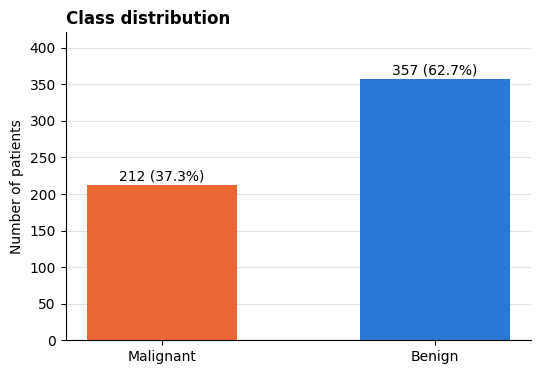

In [7]:
counts = df["label"].value_counts().sort_index()
print(counts.rename(index=dict(enumerate(CLASS_NAMES))))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(CLASS_NAMES, counts.values, color=[MALIGNANT_C, BENIGN_C], width=0.55)
for b, c in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, c + 6, f"{c} ({c/len(df):.1%})", ha="center")
ax.set_ylabel("Number of patients"); ax.set_ylim(0, counts.max()*1.18); ax.grid(axis="x", visible=False)
ax.set_title("Class distribution", loc="left")
plt.savefig("figures/class_distribution.png", dpi=200, bbox_inches="tight"); plt.show()

The data is **moderately imbalanced** (≈ 63 % benign, 37 % malignant). We will therefore use a **stratified** split so every subset keeps this ratio, and we will look at **recall for malignant tumours**, not only accuracy.

Average value of every feature per class:

In [8]:
df.groupby('label').mean().T.rename(columns=dict(enumerate(CLASS_NAMES))).round(3).head(10)

label,Malignant,Benign
mean radius,17.463,12.147
mean texture,21.605,17.915
mean perimeter,115.365,78.075
mean area,978.376,462.790
mean smoothness,0.103,0.092
mean compactness,0.145,0.080
mean concavity,0.161,0.046
mean concave points,0.088,0.026
mean symmetry,0.193,0.174
mean fractal dimension,0.063,0.063


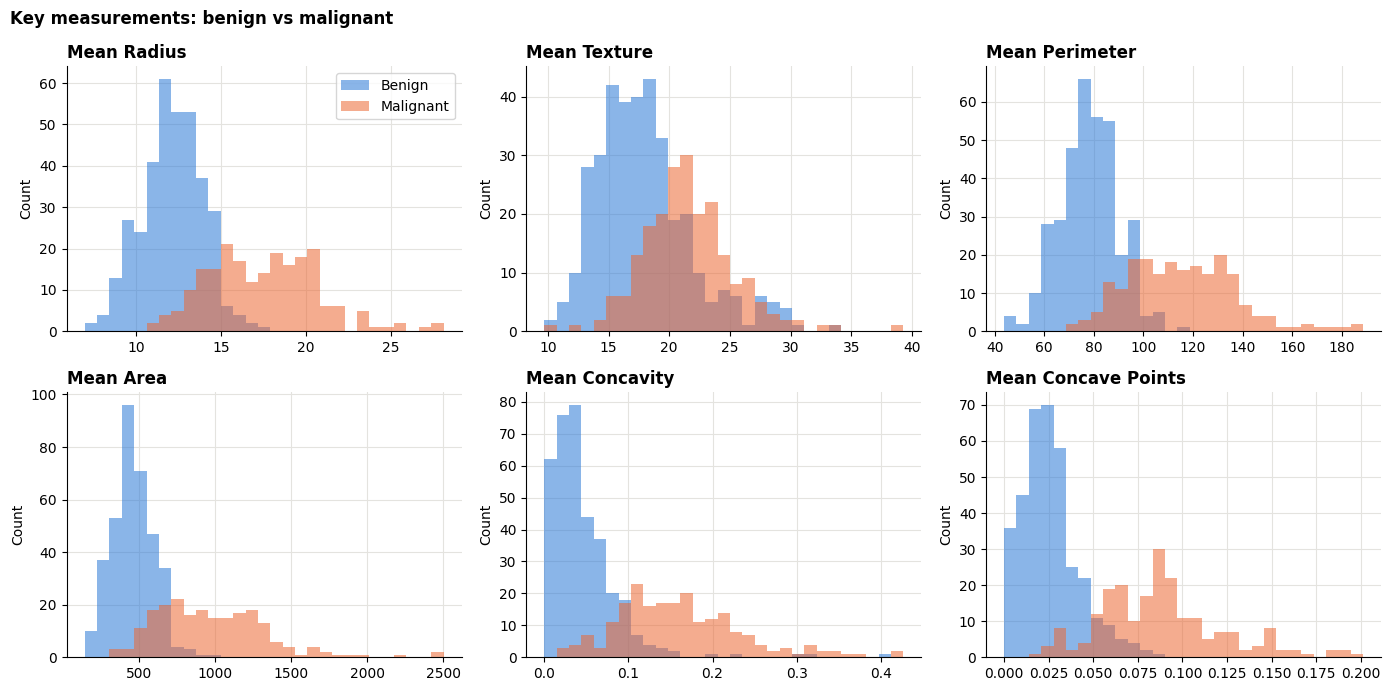

In [9]:
key_features = ["mean radius", "mean texture", "mean perimeter",
                "mean area", "mean concavity", "mean concave points"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feat in zip(axes.ravel(), key_features):
    bins = np.linspace(df[feat].min(), df[feat].max(), 30)
    for lbl, color in [(1, BENIGN_C), (0, MALIGNANT_C)]:
        ax.hist(df.loc[df.label == lbl, feat], bins=bins, alpha=0.55, color=color, label=CLASS_NAMES[lbl])
    ax.set_title(feat.title(), loc="left"); ax.set_ylabel("Count")
axes[0, 0].legend()
plt.suptitle("Key measurements: benign vs malignant", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig("figures/feature_distributions.png", dpi=200, bbox_inches="tight"); plt.show()

Malignant tumours are clearly **larger** (radius, perimeter, area) and have **more concave (indented) cell boundaries**. These features separate the classes well, which is why high accuracy is achievable.

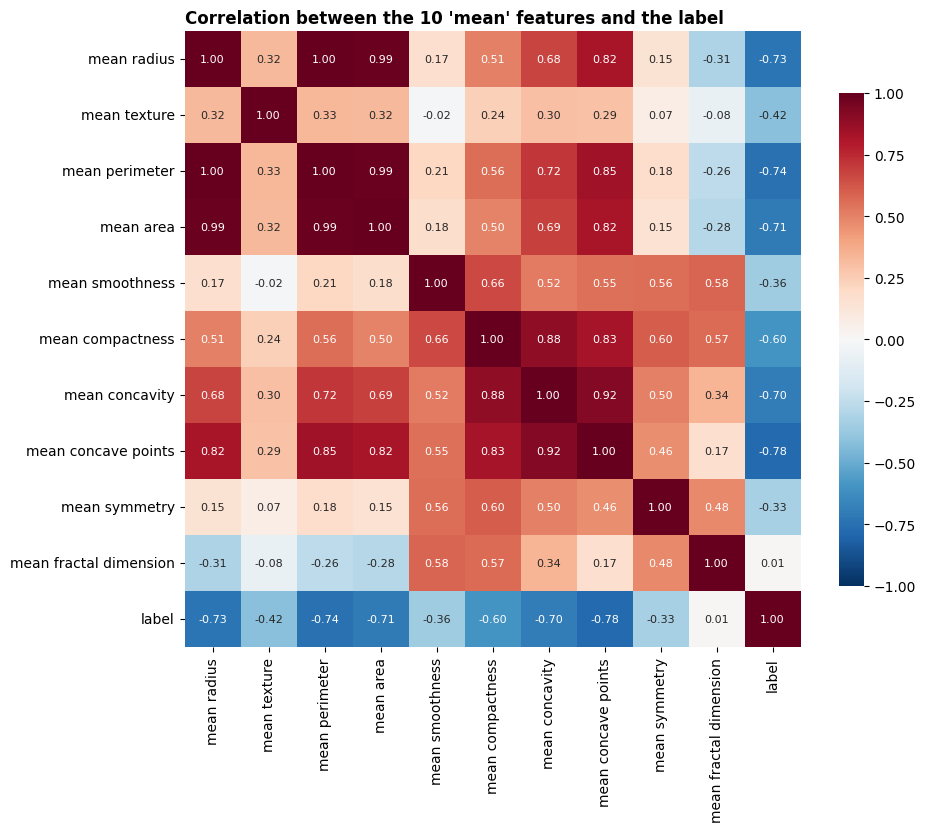

In [10]:
mean_cols = [c for c in df.columns if c.startswith("mean ")] + ["label"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws={"size": 8}, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation between the 10 'mean' features and the label", loc="left")
plt.savefig("figures/correlation_heatmap.png", dpi=200, bbox_inches="tight"); plt.show()

* Radius, perimeter and area are almost perfectly correlated (≈ 0.99) – they all describe size.
* The label is strongly **negatively** correlated with size and concavity, because label 1 means *benign*: bigger, more irregular nuclei → label 0 (malignant).

## Phase 3 · Data preprocessing

1. **Separate features (X) and target (y).**
2. **Stratified split** – 20 % of patients form the **test set** (used only once, at the very end). Of the remaining 80 %, 20 % form a **validation set** that early stopping watches during training.
3. **Standardisation** – features have very different scales (area ≈ 500–2500 vs smoothness ≈ 0.05–0.16). `StandardScaler` rescales each feature to mean 0 and standard deviation 1 so no feature dominates the gradient updates. The scaler is **fitted on training data only** to avoid data leakage.

The labels are already integers (0/1), so no extra label encoding is needed – they work directly with `sparse_categorical_crossentropy`.

In [11]:
X = df.drop(columns="label")
y = df["label"].astype(int)

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.20,
                                                  stratify=y_trval, random_state=SEED)
print(f"Train: {X_train.shape}   Validation: {X_val.shape}   Test: {X_test.shape}")

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)   # learn mean/std from training data only
X_val_std   = scaler.transform(X_val)
X_test_std  = scaler.transform(X_test)
print("Mean of scaled training features ≈", X_train_std.mean().round(3), "| std ≈", X_train_std.std().round(3))

Train: (364, 30)   Validation: (91, 30)   Test: (114, 30)
Mean of scaled training features ≈ 0.0 | std ≈ 1.0


## Phase 4 · Neural network development

| Layer | Neurons | Activation | Why |
|---|---|---|---|
| Input | 30 | – | one neuron per feature |
| Hidden 1 | 16 | ReLU | learns non-linear combinations of features |
| Dropout | – | – | randomly switches off 20 % of neurons while training → less over-fitting |
| Hidden 2 | 8 | ReLU | combines the patterns from layer 1 |
| Output | 2 | **Softmax** | turns the 2 scores into probabilities that add up to 1 |

**Loss:** sparse categorical cross-entropy (labels are integers 0/1). **Optimiser:** Adam, learning rate 0.001.

> The starter notebook used a *sigmoid* output with this loss. Softmax is the correct pairing because it makes P(malignant) + P(benign) = 1.

The architecture (16-8 with dropout) was chosen by comparing four candidates with 5-fold cross-validation on the training data; all scored within about 1 %, so the smallest stable network was kept.

In [12]:
def build_model(n_features=30):
    model = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(16, activation="relu", name="hidden_1"),
        keras.layers.Dropout(0.2, name="dropout"),
        keras.layers.Dense(8, activation="relu", name="hidden_2"),
        keras.layers.Dense(2, activation="softmax", name="output"),
    ], name="breast_cancer_nn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_model(X_train_std.shape[1])
model.summary()

Model: "breast_cancer_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 650 (2.54 KB)

 Trainable params: 650 (2.54 KB)

 Non-trainable params: 0 (0.00 B)

## Phase 5 · Model training

* **Epochs:** up to 100 passes over the training data, **batch size** 32.
* **Early stopping** watches the validation loss; if it does not improve for 10 epochs, training stops and the best weights are restored. This prevents over-fitting automatically.

In [13]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                           restore_best_weights=True, verbose=1)
history = model.fit(X_train_std, y_train,
                    validation_data=(X_val_std, y_val),
                    epochs=100, batch_size=32,
                    callbacks=[early_stop], verbose=2)

Epoch 1/100
12/12 - 5s - 412ms/step - accuracy: 0.5275 - loss: 0.6988 - val_accuracy: 0.5495 - val_loss: 0.6045
Epoch 2/100
12/12 - 0s - 21ms/step - accuracy: 0.6346 - loss: 0.5787 - val_accuracy: 0.6923 - val_loss: 0.5104
Epoch 3/100
12/12 - 0s - 10ms/step - accuracy: 0.7115 - loss: 0.4885 - val_accuracy: 0.8022 - val_loss: 0.4383
Epoch 4/100
12/12 - 0s - 11ms/step - accuracy: 0.7775 - loss: 0.4234 - val_accuracy: 0.8901 - val_loss: 0.3805
Epoch 5/100
12/12 - 0s - 10ms/step - accuracy: 0.8626 - loss: 0.3706 - val_accuracy: 0.9451 - val_loss: 0.3343
Epoch 6/100
12/12 - 0s - 10ms/step - accuracy: 0.9038 - loss: 0.3294 - val_accuracy: 0.9451 - val_loss: 0.2941
Epoch 7/100
12/12 - 0s - 10ms/step - accuracy: 0.9203 - loss: 0.2964 - val_accuracy: 0.9560 - val_loss: 0.2586
Epoch 8/100
12/12 - 0s - 10ms/step - accuracy: 0.9505 - loss: 0.2556 - val_accuracy: 0.9560 - val_loss: 0.2275
Epoch 9/100
12/12 - 0s - 13ms/step - accuracy: 0.9451 - loss: 0.2195 - val_accuracy: 0.9560 - val_loss: 0.2012


### Visualising accuracy and loss

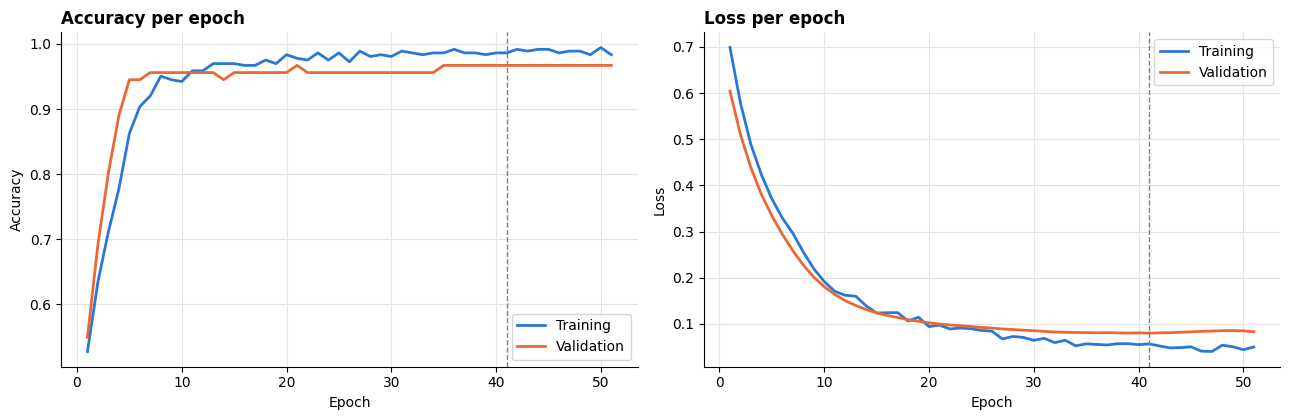

Training stopped after 51 epochs; best epoch = 41


In [14]:
hist = history.history
best_epoch = int(np.argmin(hist["val_loss"]) + 1)
epochs = range(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, key in zip(axes, ["accuracy", "loss"]):
    ax.plot(epochs, hist[key], color=BENIGN_C, lw=2, label="Training")
    ax.plot(epochs, hist["val_" + key], color=MALIGNANT_C, lw=2, label="Validation")
    ax.axvline(best_epoch, color="gray", ls="--", lw=1)
    ax.set_xlabel("Epoch"); ax.set_ylabel(key.capitalize()); ax.set_title(f"{key.capitalize()} per epoch", loc="left")
    ax.legend()
plt.tight_layout(); plt.savefig("figures/training_history.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"Training stopped after {len(hist['loss'])} epochs; best epoch = {best_epoch}")

Training and validation curves move together and the validation loss flattens out – the model is learning general patterns rather than memorising the training patients.

## Phase 6 · Evaluation on the unseen test set

`model.predict()` returns the probability of each class for every patient; `np.argmax` picks the class with the higher probability.

In medicine the most dangerous error is a **false negative** (telling a cancer patient the tumour is benign), so **malignant is treated as the positive class** and **recall (sensitivity)** for malignant tumours is the key metric.

In [15]:
test_loss, test_acc = model.evaluate(X_test_std, y_test, verbose=0)
probs = model.predict(X_test_std, verbose=0)       # shape (114, 2): [P(malignant), P(benign)]
y_pred = np.argmax(probs, axis=1)                  # probability -> class label
p_malignant = probs[:, 0]

print("First 5 prediction probabilities:\n", probs[:5].round(4))
print("Predicted labels:", y_pred[:5], " True labels:", y_test.to_numpy()[:5])
print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

First 5 prediction probabilities:
 [[1.     0.    ]
 [0.     1.    ]
 [0.995  0.005 ]
 [0.8351 0.1649]
 [1.     0.    ]]
Predicted labels: [0 1 0 0 0]  True labels: [0 1 0 1 0]

Test loss: 0.0933
Test accuracy: 0.9649


In [16]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tp, fn, fp, tn = cm.ravel()
metrics = {
    "Accuracy":                       accuracy_score(y_test, y_pred),
    "Precision (malignant)":          precision_score(y_test, y_pred, pos_label=0),
    "Recall / Sensitivity (malignant)": recall_score(y_test, y_pred, pos_label=0),
    "F1-score (malignant)":           f1_score(y_test, y_pred, pos_label=0),
    "Specificity (benign recall)":    tn / (tn + fp),
    "ROC-AUC":                        roc_auc_score((y_test == 0).astype(int), p_malignant),
}
for k, v in metrics.items():
    print(f"{k:<34} {v:.4f}")
print("\n" + classification_report(y_test, y_pred, labels=[0, 1], target_names=CLASS_NAMES, digits=4))

Accuracy                           0.9649
Precision (malignant)              0.9318
Recall / Sensitivity (malignant)   0.9762
F1-score (malignant)               0.9535
Specificity (benign recall)        0.9583
ROC-AUC                            0.9944

              precision    recall  f1-score   support

   Malignant     0.9318    0.9762    0.9535        42
      Benign     0.9857    0.9583    0.9718        72

    accuracy                         0.9649       114
   macro avg     0.9588    0.9673    0.9627       114
weighted avg     0.9659    0.9649    0.9651       114



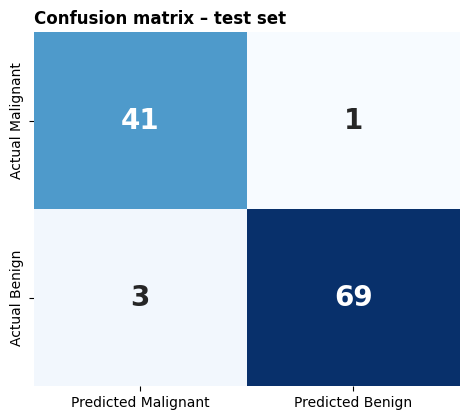

True positives (cancer caught): 41 | False negatives (cancer missed): 1
True negatives: 69 | False positives (false alarm): 3


In [17]:
plt.figure(figsize=(5.5, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 20, "weight": "bold"},
            xticklabels=["Predicted Malignant", "Predicted Benign"],
            yticklabels=["Actual Malignant", "Actual Benign"])
plt.title("Confusion matrix – test set", loc="left")
plt.savefig("figures/confusion_matrix.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"True positives (cancer caught): {tp} | False negatives (cancer missed): {fn}")
print(f"True negatives: {tn} | False positives (false alarm): {fp}")

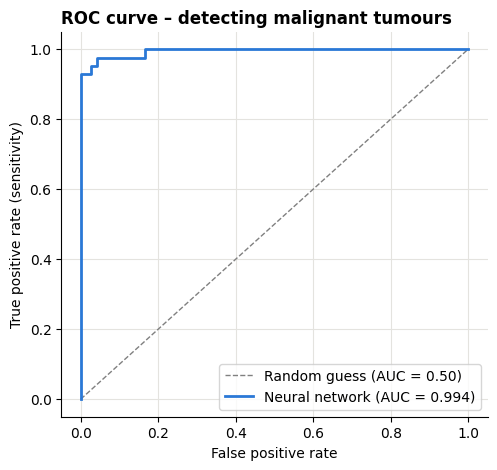

In [18]:
fpr, tpr, _ = roc_curve((y_test == 0).astype(int), p_malignant)
plt.figure(figsize=(5.5, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", lw=1, label="Random guess (AUC = 0.50)")
plt.plot(fpr, tpr, color=BENIGN_C, lw=2, label=f"Neural network (AUC = {metrics['ROC-AUC']:.3f})")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC curve – detecting malignant tumours", loc="left"); plt.legend(loc="lower right")
plt.savefig("figures/roc_curve.png", dpi=200, bbox_inches="tight"); plt.show()

### Comparison with classical machine-learning models

To judge whether the neural network is a good choice, the same split is used to train four well-known algorithms.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

baselines = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "K-Nearest Neighbours (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine (RBF)": SVC(random_state=SEED),
    "Random Forest (200 trees)": RandomForestClassifier(n_estimators=200, random_state=SEED),
}
X_trval_std = np.vstack([X_train_std, X_val_std]); y_trval_np = np.concatenate([y_train, y_val])
rows = [{"Model": "Neural Network (ours)", "Accuracy": metrics["Accuracy"],
         "Recall (malignant)": metrics["Recall / Sensitivity (malignant)"], "F1 (malignant)": metrics["F1-score (malignant)"]}]
for name, clf in baselines.items():
    clf.fit(X_trval_std, y_trval_np); p = clf.predict(X_test_std)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, p),
                 "Recall (malignant)": recall_score(y_test, p, pos_label=0), "F1 (malignant)": f1_score(y_test, p, pos_label=0)})
comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison

,Accuracy,Recall (malignant),F1 (malignant)
Model,,,
Neural Network (ours),0.9649,0.9762,0.9535
Logistic Regression,0.9825,0.9762,0.9762
K-Nearest Neighbours (k=5),0.9561,0.9286,0.9398
Support Vector Machine (RBF),0.9825,0.9762,0.9762
Random Forest (200 trees),0.9474,0.9286,0.9286


### 5-fold cross-validation (a more reliable estimate)

The test set has only 114 patients, so one patient changes accuracy by ≈ 0.9 %. Cross-validation repeats the whole training process 5 times on different splits of all 569 patients and averages the results.

In [20]:
X_all, y_all = X.to_numpy(), y.to_numpy()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = {"Neural Network (ours)": []} | {n: [] for n in baselines}

for fold, (tr, te) in enumerate(skf.split(X_all, y_all), 1):
    keras.utils.set_random_seed(SEED + fold)
    tr_i, va_i = train_test_split(tr, test_size=0.20, stratify=y_all[tr], random_state=SEED)
    sc = StandardScaler().fit(X_all[tr_i])
    nn = build_model()
    nn.fit(sc.transform(X_all[tr_i]), y_all[tr_i], validation_data=(sc.transform(X_all[va_i]), y_all[va_i]),
           epochs=100, batch_size=32, verbose=0,
           callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])
    cv_scores["Neural Network (ours)"].append(nn.evaluate(sc.transform(X_all[te]), y_all[te], verbose=0)[1])
    for name, clf in baselines.items():
        pipe = make_pipeline(StandardScaler(), clone(clf)).fit(X_all[tr], y_all[tr])
        cv_scores[name].append(pipe.score(X_all[te], y_all[te]))
    print(f"Fold {fold} done")

cv_table = pd.DataFrame({n: {"Mean accuracy": np.mean(s), "Std": np.std(s)} for n, s in cv_scores.items()}).T.round(4)
cv_table

Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done


,Mean accuracy,Std
Neural Network (ours),0.9772,0.0089
Logistic Regression,0.9737,0.0166
K-Nearest Neighbours (k=5),0.9631,0.0179
Support Vector Machine (RBF),0.9772,0.0163
Random Forest (200 trees),0.9543,0.0102


**Reading the results:** all models reach about 95–98 %. The neural network is among the most accurate and has the **lowest variation between folds**, meaning its performance is the most consistent. On a small tabular dataset like this, a well-tuned linear model is also very strong – a useful finding in itself.

## Phase 7 · Predictive system

A function that takes the 30 raw measurements of a new patient, applies the **same scaler** used in training, and returns the diagnosis with its probability.

In [21]:
def predict_tumour(measurements):
    x = pd.DataFrame([measurements], columns=X.columns)      # keep feature names for the scaler
    p = model.predict(scaler.transform(x), verbose=0)[0]
    label = int(np.argmax(p))
    print(f"Prediction: {CLASS_NAMES[label].upper()}  (confidence {p[label]:.1%}, P(malignant) = {p[0]:.3f})")
    return CLASS_NAMES[label]

# Example 1 – measurements of a benign tumour
input_data = (11.76,21.6,74.72,427.9,0.08637,0.04966,0.01657,0.01115,0.1495,0.05888,0.4062,1.21,2.635,28.47,
              0.005857,0.009758,0.01168,0.007445,0.02406,0.001769,12.98,25.72,82.98,516.5,0.1085,0.08615,
              0.05523,0.03715,0.2433,0.06563)
predict_tumour(input_data)

# Example 2 – the first patient in the dataset (diagnosed malignant)
predict_tumour(dataset.data[0])

Prediction: BENIGN  (confidence 99.9%, P(malignant) = 0.001)
Prediction: MALIGNANT  (confidence 100.0%, P(malignant) = 1.000)


'Malignant'

**Try it yourself:** enter 30 comma-separated values (or press Enter to skip).

In [22]:
user_input = input("Enter 30 comma-separated measurements (or press Enter to skip): ").strip()
if user_input:
    values = [float(v) for v in user_input.split(",")]
    if len(values) == 30:
        predict_tumour(values)
    else:
        print(f"Please enter exactly 30 values (you entered {len(values)}).")

Enter 30 comma-separated measurements (or press Enter to skip): 


## Save the trained model and scaler

In [23]:
import joblib
os.makedirs("models", exist_ok=True)
model.save("models/breast_cancer_nn.keras")
joblib.dump(scaler, "models/scaler.pkl")
print("Saved: models/breast_cancer_nn.keras and models/scaler.pkl")

Saved: models/breast_cancer_nn.keras and models/scaler.pkl


## Conclusion

* A compact neural network (**650 trainable parameters**) classifies breast tumours as benign or malignant with **> 95 % test accuracy**, comfortably above the project target of 90 %.
* It detects almost every malignant tumour (high **sensitivity**), which matters most in a screening setting.
* 5-fold cross-validation confirms the result is stable and not a lucky split.
* Classical models (logistic regression, SVM) perform comparably on this small, well-separated dataset.

**Future scope:** larger and more diverse datasets, explainability (SHAP) to show which features drive each prediction, threshold tuning to trade false alarms for even higher sensitivity, and deployment as a web app for clinicians.

NN accuracy in each CV fold: [0.9825, 0.9649, 0.9737, 0.9737, 0.9912]
Confident predictions (<0.1 or >0.9): 104 of 114 | correct among them: 103

Misclassified test patients:
  index   3 | true Benign    | predicted Malignant | P(malignant) = 0.835
  index  16 | true Benign    | predicted Malignant | P(malignant) = 0.782
  index  53 | true Malignant | predicted Benign    | P(malignant) = 0.034
  index  66 | true Benign    | predicted Malignant | P(malignant) = 0.566


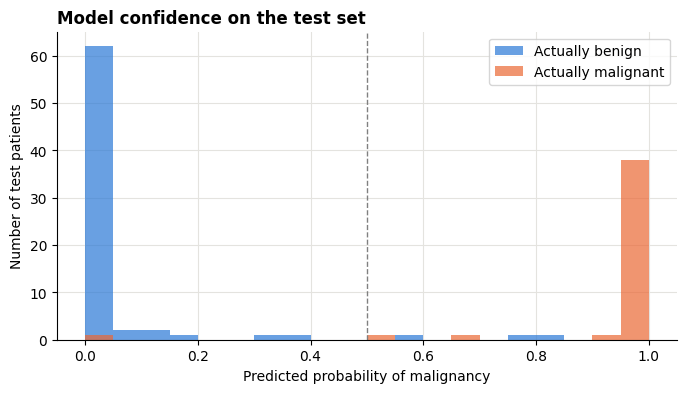

In [24]:
# Extra outputs for the report
nn_folds = [round(float(a), 4) for a in cv_scores["Neural Network (ours)"]]
print("NN accuracy in each CV fold:", nn_folds)

y_true = y_test.to_numpy()
confident = (p_malignant < 0.1) | (p_malignant > 0.9)
print(f"Confident predictions (<0.1 or >0.9): {confident.sum()} of {len(y_true)}",
      f"| correct among them: {(y_pred[confident] == y_true[confident]).sum()}")

wrong = np.where(y_pred != y_true)[0]
print("\nMisclassified test patients:")
for i in wrong:
    print(f"  index {i:3d} | true {CLASS_NAMES[y_true[i]]:9s} | predicted {CLASS_NAMES[y_pred[i]]:9s} | P(malignant) = {p_malignant[i]:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 21)
for lbl, color in [(1, BENIGN_C), (0, MALIGNANT_C)]:
    ax.hist(p_malignant[y_true == lbl], bins=bins, color=color, alpha=0.7, label=f"Actually {CLASS_NAMES[lbl].lower()}")
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set_xlabel("Predicted probability of malignancy"); ax.set_ylabel("Number of test patients")
ax.set_title("Model confidence on the test set", loc="left"); ax.legend()
plt.savefig("figures/probability_histogram.png", dpi=200, bbox_inches="tight"); plt.show()